In [1]:
pip install ultralytics

Note: you may need to restart the kernel to use updated packages.


WARNING Unable to automatically guess model task, assuming 'task=detect'. Explicitly define task for your model, i.e. 'task=detect', 'segment', 'classify', 'pose', 'obb' or 'semantic'.
Loading E:\EP - project\best.onnx for ONNX Runtime inference...
requirements: Ultralytics requirements ['onnx', 'onnxruntime'] not found, attempting AutoUpdate...
   ---------------------------------------- 0.0/17.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.2 MB ? eta -:--:--
    --------------------------------------- 0.3/17.2 MB ? eta -:--:--
   - -------------------------------------- 0.8/17.2 MB 2.5 MB/s eta 0:00:07
   --- ------------------------------------ 1.3/17.2 MB 2.4 MB/s eta 0:00:07
   --- ------------------------------------ 1.6/17.2 MB 2.4 MB/s eta 0:00:07
   ---- ----------------------------------- 2.1/17.2 MB 2.1 MB/s eta 0:00:08
   ------ --------------------------------- 2.9/17.2 MB 2.3 MB/s eta 0:00:07
   -------- ------------------------------- 3.7/17.2 MB 2

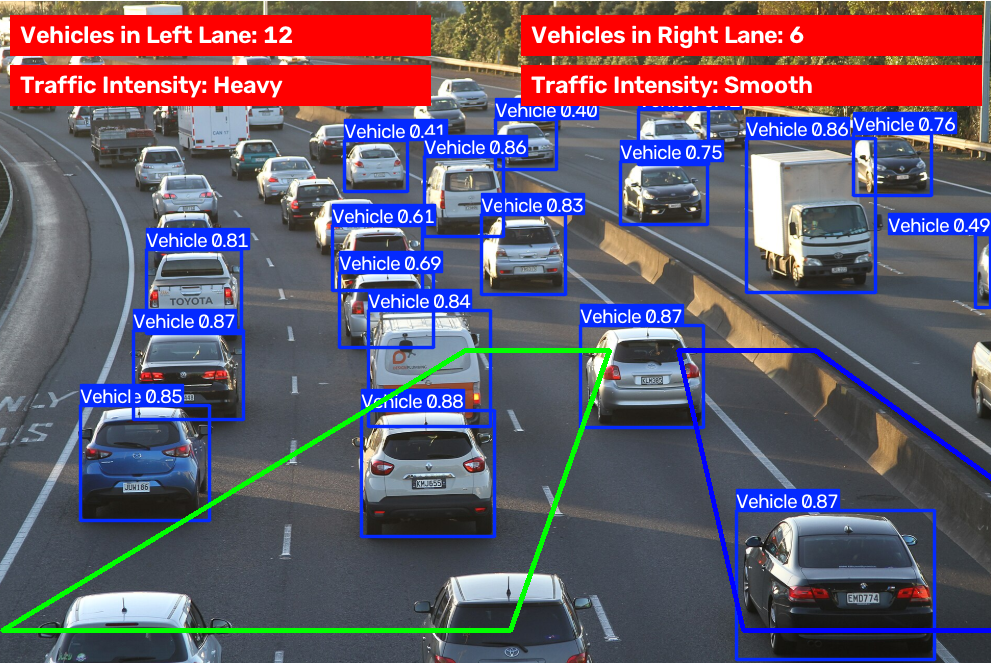


        TRAFFIC DENSITY RESULT

Vehicles in Left Lane: 12
Traffic Intensity: Heavy

Vehicles in Right Lane: 6
Traffic Intensity: Smooth



In [3]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image
import numpy as np
import cv2
import os

# ============================================================
# 1. Load your exported ONNX model
# ============================================================

onnx_model_path = r"E:\EP - project\best.onnx"

model = YOLO(onnx_model_path)

# ============================================================
# 2. Give the path of the image you want to test
# ============================================================

image_path = r"E:\EP - project\testt.png"

# ============================================================
# 3. Traffic settings
# ============================================================

# Number of vehicles above which traffic is considered Heavy
heavy_traffic_threshold = 10

# Lane regions
vertices1 = np.array(
    [(465, 350), (609, 350), (510, 630), (2, 630)],
    dtype=np.int32
)

vertices2 = np.array(
    [(678, 350), (815, 350), (1203, 630), (743, 630)],
    dtype=np.int32
)

# X-coordinate used to separate left and right lanes
lane_threshold = 609

# ============================================================
# 4. Check if image exists
# ============================================================

if not os.path.exists(image_path):

    print("Image not found:")
    print(image_path)

else:

    # ========================================================
    # 5. Run YOLO detection
    # ========================================================

    results = model.predict(
        source=image_path,
        imgsz=512,
        conf=0.4,
        save=False,
        verbose=False
    )

    # Get original image
    original_image = cv2.imread(image_path)

    # Get YOLO annotated image
    result_image = results[0].plot(line_width=2)

    # ========================================================
    # 6. Count vehicles in left and right lanes
    # ========================================================

    bounding_boxes = results[0].boxes

    vehicles_in_left_lane = 0
    vehicles_in_right_lane = 0

    for box in bounding_boxes.xyxy:

        # Get left X coordinate of bounding box
        x1_box = box[0].item()

        if x1_box < lane_threshold:
            vehicles_in_left_lane += 1
        else:
            vehicles_in_right_lane += 1

    # ========================================================
    # 7. Determine traffic intensity
    # ========================================================

    traffic_intensity_left = (
        "Heavy"
        if vehicles_in_left_lane > heavy_traffic_threshold
        else "Smooth"
    )

    traffic_intensity_right = (
        "Heavy"
        if vehicles_in_right_lane > heavy_traffic_threshold
        else "Smooth"
    )

    # ========================================================
    # 8. Draw lane regions
    # ========================================================

    cv2.polylines(
        result_image,
        [vertices1],
        isClosed=True,
        color=(0, 255, 0),
        thickness=3
    )

    cv2.polylines(
        result_image,
        [vertices2],
        isClosed=True,
        color=(255, 0, 0),
        thickness=3
    )

    # ========================================================
    # 9. Add traffic information to image
    # ========================================================

    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.8
    font_color = (255, 255, 255)
    background_color = (0, 0, 255)

    # Left lane information
    cv2.rectangle(
        result_image,
        (10, 15),
        (430, 55),
        background_color,
        -1
    )

    cv2.putText(
        result_image,
        f"Vehicles in Left Lane: {vehicles_in_left_lane}",
        (20, 43),
        font,
        font_scale,
        font_color,
        2,
        cv2.LINE_AA
    )

    cv2.rectangle(
        result_image,
        (10, 65),
        (430, 105),
        background_color,
        -1
    )

    cv2.putText(
        result_image,
        f"Traffic Intensity: {traffic_intensity_left}",
        (20, 93),
        font,
        font_scale,
        font_color,
        2,
        cv2.LINE_AA
    )

    # Right lane information
    image_width = result_image.shape[1]

    cv2.rectangle(
        result_image,
        (image_width - 470, 15),
        (image_width - 10, 55),
        background_color,
        -1
    )

    cv2.putText(
        result_image,
        f"Vehicles in Right Lane: {vehicles_in_right_lane}",
        (image_width - 460, 43),
        font,
        font_scale,
        font_color,
        2,
        cv2.LINE_AA
    )

    cv2.rectangle(
        result_image,
        (image_width - 470, 65),
        (image_width - 10, 105),
        background_color,
        -1
    )

    cv2.putText(
        result_image,
        f"Traffic Intensity: {traffic_intensity_right}",
        (image_width - 460, 93),
        font,
        font_scale,
        font_color,
        2,
        cv2.LINE_AA
    )

    # ========================================================
    # 10. Display the image
    # ========================================================

    display(
        Image.fromarray(
            cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)
        )
    )

    # ========================================================
    # 11. Print traffic results
    # ========================================================

    print("\n========================================")
    print("        TRAFFIC DENSITY RESULT")
    print("========================================")

    print(f"\nVehicles in Left Lane: {vehicles_in_left_lane}")
    print(f"Traffic Intensity: {traffic_intensity_left}")

    print(f"\nVehicles in Right Lane: {vehicles_in_right_lane}")
    print(f"Traffic Intensity: {traffic_intensity_right}")

    print("\n========================================")